# 06 · Low-confidence Kaggle images

The best model so far (`E04_contrast_aug` + AdaBN balanced, **68.18%** on Kaggle) scores 98.8% on
EuroSAT, so roughly one in three Kaggle images is classified wrongly. The Kaggle labels are unknown,
so the wrong images can't be listed directly. This notebook looks at the next best thing: **the
images the model is unsure about**.

**Questions**

1. How confident is the model on Kaggle images, compared with EuroSAT images it gets right?
2. Which classes and which class *pairs* are the uncertain predictions spread over?
3. Do the other good models (Fourier `E05a`–`E05c`, 66–68%) disagree on the same images?
4. What do the uncertain images look like next to EuroSAT examples of the two candidate classes?
5. Are uncertain images special in brightness, contrast or water share?

**Measures per image** (all from the 8 rotated/flipped views, averaged = TTA)

| Measure | Meaning |
|---|---|
| `conf` | probability of the predicted class |
| `margin` | probability of the 1st minus the 2nd class (small = torn between two classes) |
| `view_agree` | all 8 views predict the same class |
| `model_agree` | number of the 4 models (E04, E05a, E05b, E05c, each with AdaBN) that predict the same class as E04 |

No training, no submission: only saved weights are loaded. The table of measures is saved to
`artifacts/kaggle_confidence.csv`, for example to choose pseudo-labels later.

## 1 · Setup and data

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
from src.data import CLASSES, PROJECT_ROOT, TEST_BANDS, band_index, load_split, load_test, load_train
from src.experiment import find_run, load_correction
from src.plot_style import MUTED, TEST_COLOR, TRAIN_COLOR, apply_style
from src.preprocessing import land_mask
from src.training import load_run, predict_views, to_device_images
from src.utils import get_device

apply_style()
device = get_device()

# ---- Settings --------------------------------------------------------------------------
MAIN_RUN = "adabn_balanced_contrast_aug_hist_split_effb0"          # E04 + AdaBN, 68.18%
OTHER_RUNS = {                                                     # for model agreement
    "E05a FDA": "adabn_balanced_fda_contrast_aug_hist_split_effb0",
    "E05b spectral": "adabn_balanced_spectral_contrast_aug_hist_split_effb0",
    "E05c low-freq": "adabn_balanced_lowfreq_eq_contrast_aug_hist_split_effb0",
}
LOW_CONF = 0.6   # below this, an image counts as "uncertain"

X_kaggle, test_ids = load_test()
X_kg = np.asarray(X_kaggle)
kg_images = to_device_images(X_kg, device)

# EuroSAT internal test split (hist_split-corrected, as the models saw it) as a reference
X_all, _ = load_train()
split = load_split()
te_rows = np.flatnonzero(split["split"].values == "test")
X_te = load_correction("hist_split")(np.asarray(X_all[te_rows]))
y_te = split["label_id"].values[te_rows]
print(f"Kaggle images {len(X_kg):,}   EuroSAT internal test {len(X_te):,}")

Kaggle images 4,232   EuroSAT internal test 4,050


## 2 · Predictions of the four models

In [2]:
def views_of(name_suffix, images):
    run_dir = find_run(name_suffix)
    model, normalizer, config = load_run(run_dir, device)
    assert config["bands"] == list(TEST_BANDS)
    print("loaded", run_dir.relative_to(PROJECT_ROOT))
    return predict_views(model, images, normalizer)

views = views_of(MAIN_RUN, kg_images)                 # (8, N, 10)
prob = views.mean(0)
other_pred = {k: views_of(v, kg_images).mean(0).argmax(1) for k, v in OTHER_RUNS.items()}

# Same model on the EuroSAT internal test set, as a reference for "normal" confidence
te_prob = views_of(MAIN_RUN, to_device_images(X_te, device)).mean(0)

order = np.argsort(-prob, axis=1)
pred, second = order[:, 0], order[:, 1]
rows = np.arange(len(prob))
kg = pd.DataFrame({
    "test_id": test_ids["test_id"].values,
    "pred": np.array(CLASSES)[pred],
    "second": np.array(CLASSES)[second],
    "conf": prob[rows, pred],
    "margin": prob[rows, pred] - prob[rows, second],
    "view_agree": (views.argmax(2) == pred).all(0),
    "model_agree": 1 + sum((p == pred) for p in other_pred.values()),
    "water": ~land_mask(X_kg),
})
kg.head()

loaded runs/2026-10-12_1040_adabn_balanced_contrast_aug_hist_split_effb0


loaded runs/2026-10-12_1153_adabn_balanced_fda_contrast_aug_hist_split_effb0


loaded runs/2026-10-12_1131_adabn_balanced_spectral_contrast_aug_hist_split_effb0


loaded runs/2026-10-12_1214_adabn_balanced_lowfreq_eq_contrast_aug_hist_split_effb0


loaded runs/2026-10-12_1040_adabn_balanced_contrast_aug_hist_split_effb0


,test_id,pred,second,conf,margin,view_agree,model_agree,water
0,0,PermanentCrop,Forest,0.694903,0.594817,True,3,False
1,1,River,Residential,0.742309,0.681382,True,4,False
2,2,HerbaceousVegetation,Forest,0.491886,0.297488,False,2,False
3,3,SeaLake,Residential,0.904135,0.892724,True,4,True
4,4,River,HerbaceousVegetation,0.458990,0.180195,False,3,False


## 3 · How confident is the model?

Left: confidence on Kaggle vs on EuroSAT (internal test). Right: on EuroSAT, the model is almost
never wrong when it is confident, which shows how much a low confidence means.

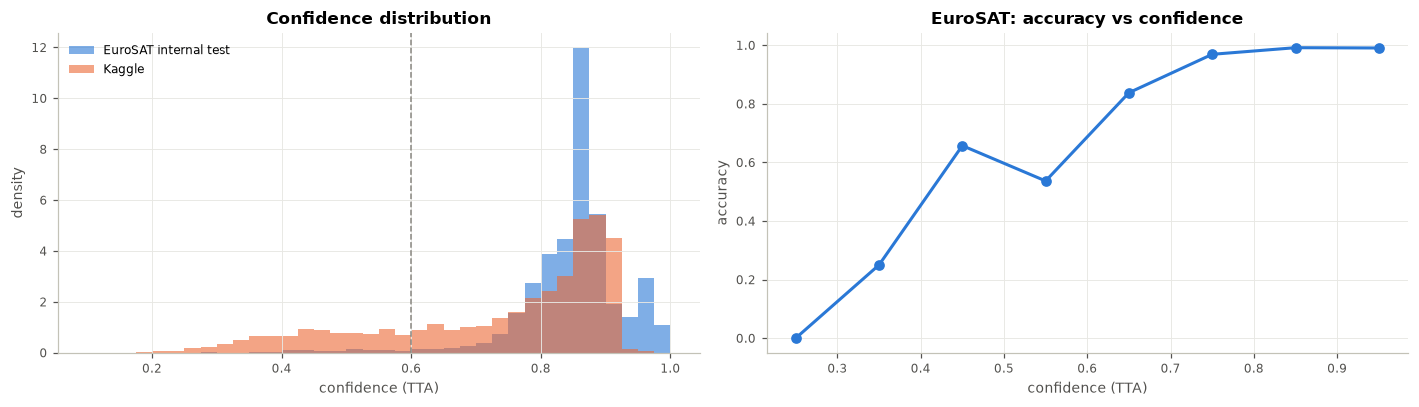

Mean confidence: EuroSAT 85.0%, Kaggle 73.6%
Share below 0.6: EuroSAT 2.0%, Kaggle 22.7%
All 8 views agree: 72.5%   all 4 models agree: 79.0%


In [3]:
te_conf = te_prob.max(1)
te_right = te_prob.argmax(1) == y_te
bins = np.linspace(0.1, 1, 37)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].hist(te_conf, bins, density=True, alpha=0.6, color=TRAIN_COLOR, label="EuroSAT internal test")
axes[0].hist(kg["conf"], bins, density=True, alpha=0.6, color=TEST_COLOR, label="Kaggle")
axes[0].axvline(LOW_CONF, color=MUTED, ls="--", lw=1)
axes[0].set(xlabel="confidence (TTA)", ylabel="density", title="Confidence distribution")
axes[0].legend()

edges = np.linspace(0.1, 1, 10)
b = np.clip(np.digitize(te_conf, edges) - 1, 0, len(edges) - 2)
acc = pd.Series(te_right).groupby(b).mean()
axes[1].plot((edges[:-1] + edges[1:])[acc.index] / 2, acc.values, "o-", color=TRAIN_COLOR)
axes[1].set(xlabel="confidence (TTA)", ylabel="accuracy", title="EuroSAT: accuracy vs confidence")
plt.tight_layout()
plt.show()

print(f"Mean confidence: EuroSAT {te_conf.mean():.1%}, Kaggle {kg['conf'].mean():.1%}")
print(f"Share below {LOW_CONF}: EuroSAT {(te_conf < LOW_CONF).mean():.1%}, Kaggle {(kg['conf'] < LOW_CONF).mean():.1%}")
print(f"All 8 views agree: {kg['view_agree'].mean():.1%}   all 4 models agree: {(kg['model_agree'] == 4).mean():.1%}")

## 4 · Which classes are uncertain?

Per predicted class: how many images, their confidence, and how often the other models agree.
A class with many predictions but low confidence and low agreement is where most errors probably sit.

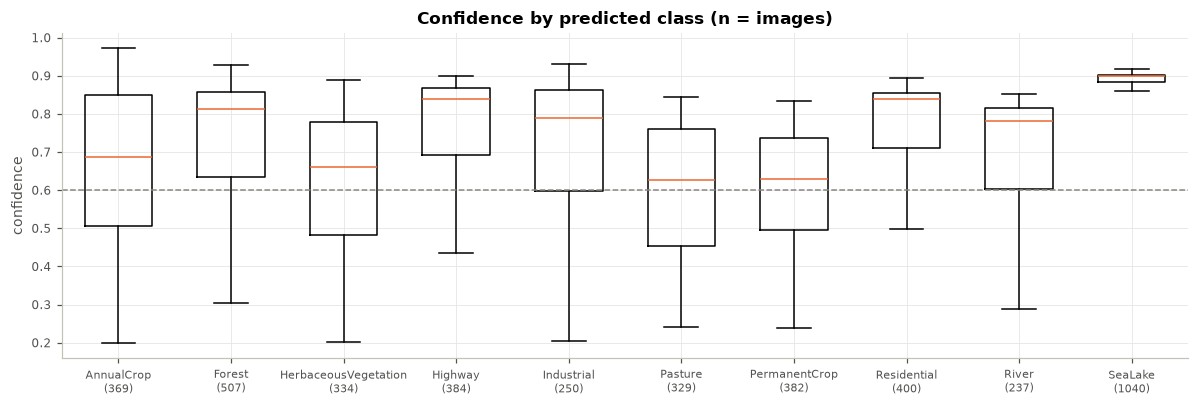

,n,mean_conf,uncertain,all_models_agree,share_%
pred,,,,,
AnnualCrop,369,0.667,0.393,0.656,8.719
Forest,507,0.730,0.227,0.793,11.980
HerbaceousVegetation,334,0.628,0.410,0.584,7.892
Highway,384,0.755,0.174,0.836,9.074
Industrial,250,0.715,0.256,0.788,5.907
Pasture,329,0.602,0.453,0.550,7.774
PermanentCrop,382,0.607,0.427,0.675,9.026
Residential,400,0.763,0.140,0.808,9.452
River,237,0.700,0.249,0.797,5.600


In [4]:
per_class = kg.groupby("pred").agg(
    n=("conf", "size"), mean_conf=("conf", "mean"),
    uncertain=("conf", lambda c: (c < LOW_CONF).mean()),
    all_models_agree=("model_agree", lambda a: (a == 4).mean()),
).reindex(CLASSES)
per_class["share_%"] = per_class["n"] / len(kg) * 100

fig, ax = plt.subplots(figsize=(11, 3.8))
data = [kg.loc[kg["pred"] == c, "conf"] for c in CLASSES]
ax.boxplot(data, showfliers=False, widths=0.6, medianprops={"color": TEST_COLOR})
ax.set_xticks(range(1, 11), [f"{c}\n({n})" for c, n in zip(CLASSES, per_class["n"])], fontsize=7)
ax.axhline(LOW_CONF, color=MUTED, ls="--", lw=1)
ax.set(ylabel="confidence", title="Confidence by predicted class (n = images)")
plt.tight_layout()
plt.show()
per_class.round(3)

### Which pairs is the model torn between?

For uncertain images (`conf < LOW_CONF`): predicted class (rows) vs second choice (columns).
Large cells are the confusions to look at.

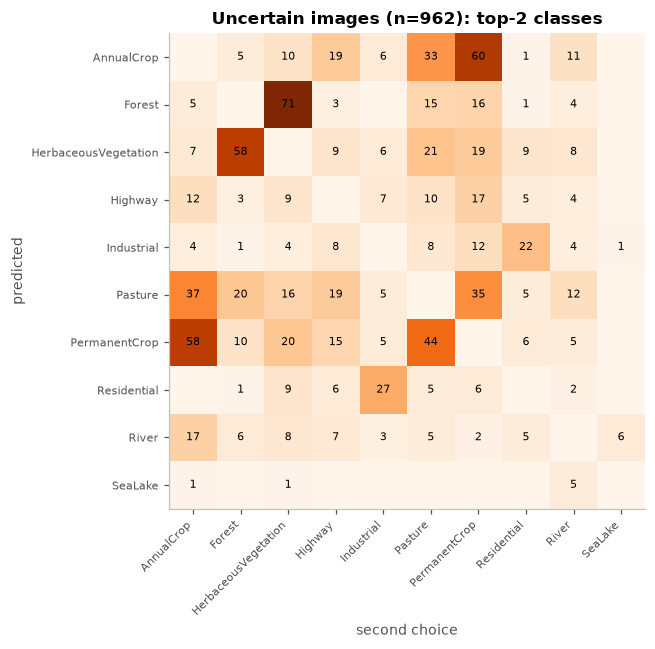

,uncertain images
Forest / HerbaceousVegetation,129
AnnualCrop / PermanentCrop,118
Pasture / PermanentCrop,79
AnnualCrop / Pasture,70
Industrial / Residential,49
HerbaceousVegetation / PermanentCrop,39
HerbaceousVegetation / Pasture,37
Forest / Pasture,35
Highway / PermanentCrop,32
AnnualCrop / Highway,31


In [5]:
low = kg[kg["conf"] < LOW_CONF]
pairs = pd.crosstab(low["pred"], low["second"]).reindex(index=CLASSES, columns=CLASSES, fill_value=0)

fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(pairs.values, cmap="Oranges")
for i in range(10):
    for j in range(10):
        if pairs.values[i, j]:
            ax.text(j, i, pairs.values[i, j], ha="center", va="center", fontsize=7)
ax.set_xticks(range(10), CLASSES, rotation=45, ha="right", fontsize=7)
ax.set_yticks(range(10), CLASSES, fontsize=7)
ax.set(xlabel="second choice", ylabel="predicted", title=f"Uncertain images (n={len(low)}): top-2 classes")
ax.grid(False)
plt.tight_layout()
plt.show()

# Unordered pairs, most frequent first
pair_names = low.apply(lambda r: " / ".join(sorted([r["pred"], r["second"]])), axis=1)
top_pairs = pair_names.value_counts()
top_pairs.head(10).to_frame("uncertain images")

## 5 · Do the other models disagree on the same images?

If the four models disagree mostly where E04 is unsure, confidence is a useful error signal
(and a good filter for pseudo-labels).

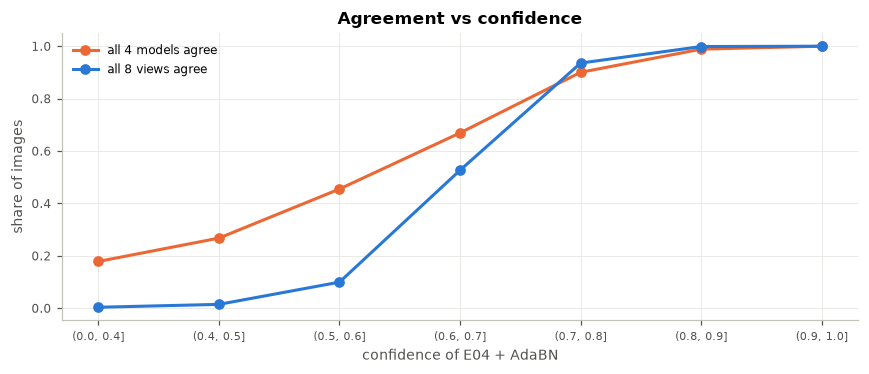

,n,all_4_models_agree,all_8_views_agree
conf,,,
"(0.0, 0.4]",286,0.178,0.003
"(0.4, 0.5]",344,0.267,0.015
"(0.5, 0.6]",332,0.455,0.099
"(0.6, 0.7]",414,0.669,0.527
"(0.7, 0.8]",653,0.900,0.936
"(0.8, 0.9]",1705,0.989,0.999
"(0.9, 1.0]",498,1.000,1.000


In [6]:
cb = pd.cut(kg["conf"], [0, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
agree = kg.groupby(cb, observed=True).agg(
    n=("conf", "size"),
    all_4_models_agree=("model_agree", lambda a: (a == 4).mean()),
    all_8_views_agree=("view_agree", "mean"),
)
fig, ax = plt.subplots(figsize=(8, 3.5))
x = np.arange(len(agree))
ax.plot(x, agree["all_4_models_agree"], "o-", color=TEST_COLOR, label="all 4 models agree")
ax.plot(x, agree["all_8_views_agree"], "o-", color=TRAIN_COLOR, label="all 8 views agree")
ax.set_xticks(x, [str(i) for i in agree.index], fontsize=7)
ax.set(xlabel="confidence of E04 + AdaBN", ylabel="share of images", title="Agreement vs confidence")
ax.legend()
plt.tight_layout()
plt.show()
agree.round(3)

## 6 · What do the uncertain images look like?

For the most frequent pairs: the least confident Kaggle images (top row) next to random EuroSAT
images of each of the two classes (bottom rows). Each image is stretched to its own 2nd–98th
percentile, so brightness differences between the datasets don't hide the structure.

Left: true colour (B04/B03/B02). Change `VIEW` to `"false"` for false colour (B08/B04/B03:
vegetation is red), which often separates crops and pastures better.

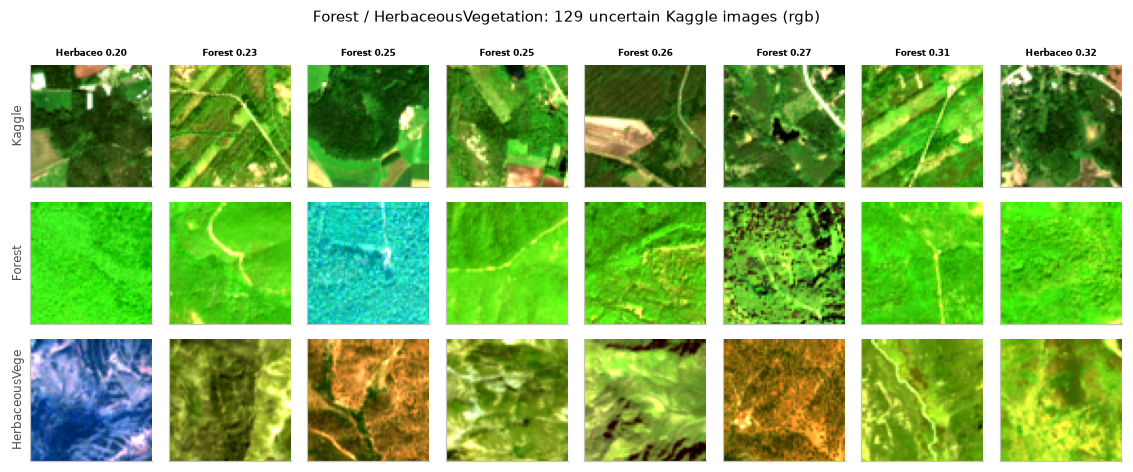

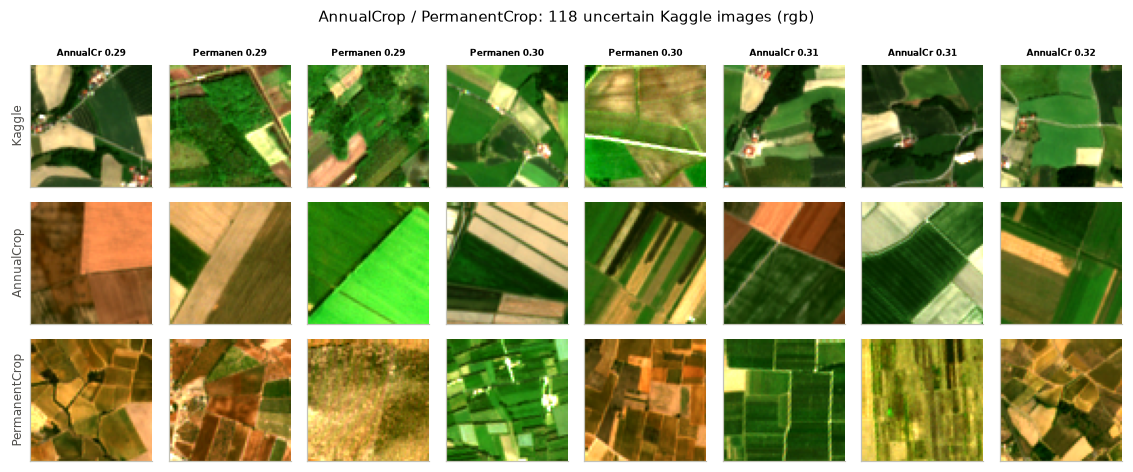

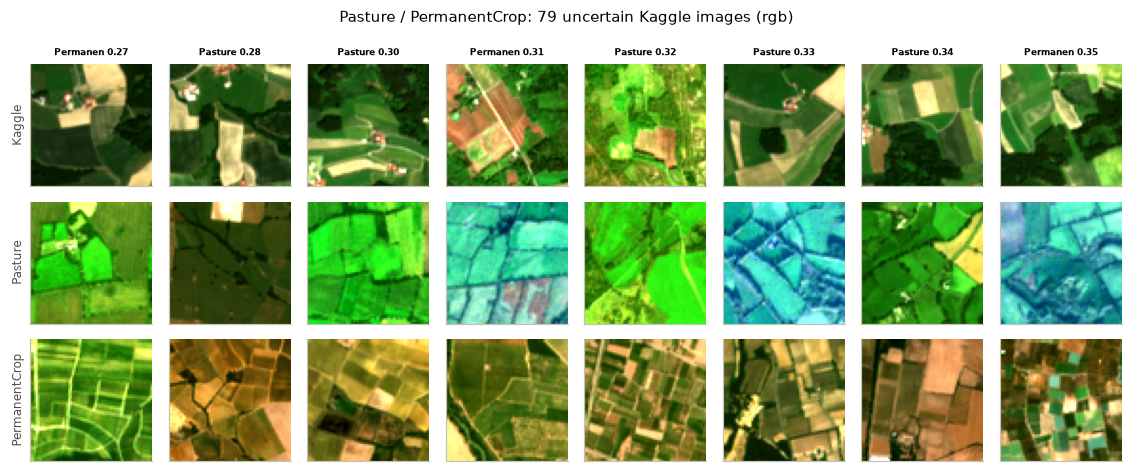

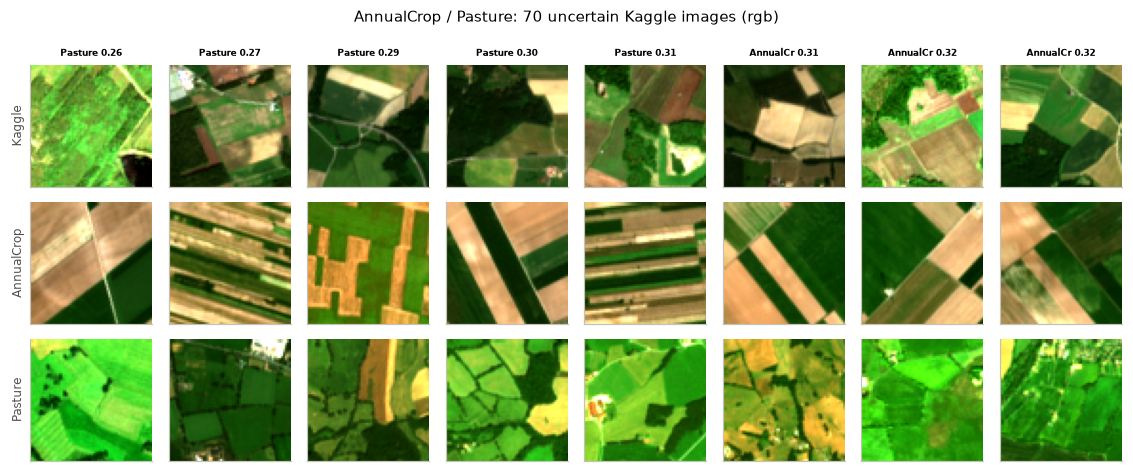

In [7]:
VIEW = "rgb"         # "rgb" or "false"
N_PAIRS, N_SHOW = 4, 8
VIEW_BANDS = {"rgb": ["B04", "B03", "B02"], "false": ["B08", "B04", "B03"]}[VIEW]
vis_idx = [band_index(b) for b in VIEW_BANDS]
rng = np.random.default_rng(0)


def to_display(img):
    x = img[vis_idx].astype(np.float32)
    lo, hi = np.percentile(x, [2, 98])
    return np.clip((x - lo) / max(hi - lo, 1), 0, 1).transpose(1, 2, 0)


for pair in top_pairs.index[:N_PAIRS]:
    a, b = pair.split(" / ")
    sel = low[pair_names == pair].sort_values("conf").head(N_SHOW)
    fig, axes = plt.subplots(3, N_SHOW, figsize=(N_SHOW * 1.3, 4.4))
    for k in range(N_SHOW):
        for r in range(3):
            axes[r, k].set_xticks([]); axes[r, k].set_yticks([]); axes[r, k].grid(False)
        if k < len(sel):
            row = sel.iloc[k]
            axes[0, k].imshow(to_display(X_kg[row.name]))
            axes[0, k].set_title(f"{row['pred'][:8]} {row['conf']:.2f}", fontsize=6)
        for r, cls in [(1, a), (2, b)]:
            i = rng.choice(np.flatnonzero(y_te == CLASSES.index(cls)))
            axes[r, k].imshow(to_display(X_te[i]))
    axes[0, 0].set_ylabel("Kaggle", fontsize=8)
    axes[1, 0].set_ylabel(a[:14], fontsize=8)
    axes[2, 0].set_ylabel(b[:14], fontsize=8)
    fig.suptitle(f"{pair}: {top_pairs[pair]} uncertain Kaggle images ({VIEW})", fontsize=10)
    plt.tight_layout()
    plt.show()

## 7 · Are uncertain images different in brightness, contrast or water?

Simple per-image measures for Kaggle images, split into confident and uncertain ones. A clear
difference points to a correction that is still missing (for example: uncertain images are much
brighter → the histogram matching doesn't cover them).

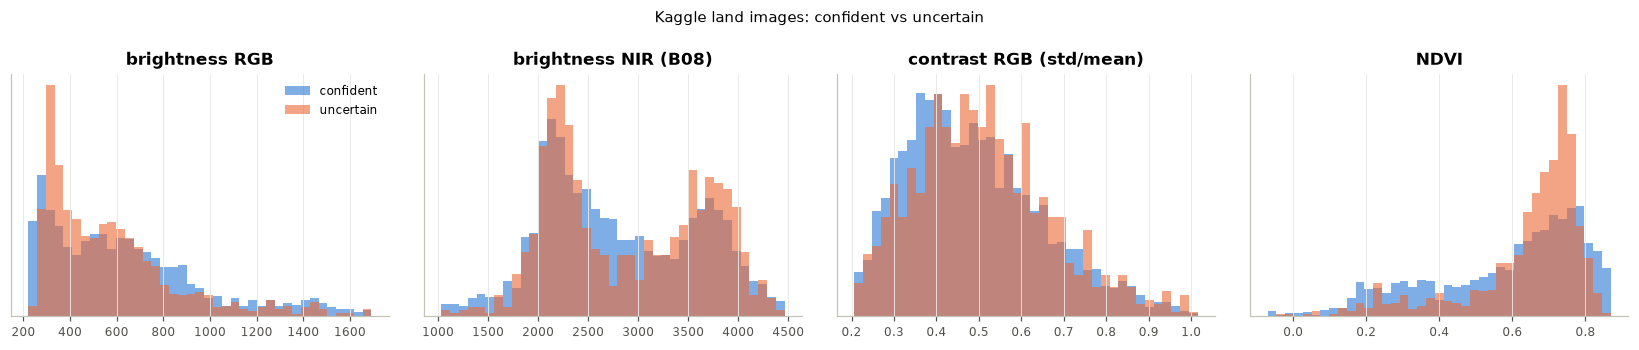

Uncertain share: water images 0.0%, land images 29.7%


,brightness RGB,brightness NIR (B08),contrast RGB (std/mean),NDVI
confident,575.757019,2669.093018,0.468,0.649
uncertain,511.891998,2784.966064,0.496,0.694


In [8]:
land = land_mask(X_kg)
x = X_kg.astype(np.float32)
feat = pd.DataFrame({
    "brightness RGB": x[:, [band_index(b) for b in ["B02", "B03", "B04"]]].mean(axis=(1, 2, 3)),
    "brightness NIR (B08)": x[:, band_index("B08")].mean(axis=(1, 2)),
    "contrast RGB (std/mean)": (x[:, [band_index(b) for b in ["B02", "B03", "B04"]]].std(axis=(2, 3))
                                / (x[:, [band_index(b) for b in ["B02", "B03", "B04"]]].mean(axis=(2, 3)) + 1)).mean(1),
    "NDVI": ((x[:, band_index("B08")] - x[:, band_index("B04")])
             / (x[:, band_index("B08")] + x[:, band_index("B04")] + 1)).mean(axis=(1, 2)),
})
del x
is_low = (kg["conf"] < LOW_CONF).values

fig, axes = plt.subplots(1, len(feat.columns), figsize=(15, 3.2))
for ax, col in zip(axes, feat.columns):
    v = feat[col].values[land]
    lo, hi = np.percentile(v, [1, 99])
    bins = np.linspace(lo, hi, 40)
    ax.hist(v[~is_low[land]], bins, density=True, alpha=0.6, color=TRAIN_COLOR, label="confident")
    ax.hist(v[is_low[land]], bins, density=True, alpha=0.6, color=TEST_COLOR, label="uncertain")
    ax.set(title=col, yticks=[])
axes[0].legend()
fig.suptitle("Kaggle land images: confident vs uncertain", fontsize=10)
plt.tight_layout()
plt.show()

print(f"Uncertain share: water images {is_low[~land].mean():.1%}, land images {is_low[land].mean():.1%}")
feat[land].groupby(np.where(is_low[land], "uncertain", "confident")).median().round(3)  # land only

## 8 · Save the measures

In [9]:
out = PROJECT_ROOT / "artifacts" / "kaggle_confidence.csv"
kg.round(4).to_csv(out, index=False)
print("Saved", out.relative_to(PROJECT_ROOT), kg.shape)

Saved artifacts/kaggle_confidence.csv (4232, 8)


## 9 · Conclusion

- **The model is unsure about a large share of Kaggle images:** 22.7% fall below 0.6 confidence, vs 2.0%
  on EuroSAT, where it is almost always right when confident. Water is never the problem
  (SeaLake: 0.7% uncertain, 99.5% model agreement).
- **The uncertainty sits in the vegetation and crop classes.** Pasture, PermanentCrop,
  HerbaceousVegetation and AnnualCrop are uncertain 39–45% of the time and the four models agree on them
  only 55–68% of the time. The top pairs are Forest/HerbaceousVegetation (129), AnnualCrop/PermanentCrop (118),
  Pasture/PermanentCrop (79) and AnnualCrop/Pasture (70). Industrial/Residential (49) is the only
  pair without vegetation.
- **Confidence is a good error signal.** Above 0.8 confidence, all four models agree on 99% of the images; below 0.5,
  on fewer than 27%. Confidence, view agreement and model agreement point to the same images,
  so they are a reliable filter for **pseudo-labels** (about 2,200 images ≥ 0.8).
- **The images show a different kind of scene, not just different colours.** Many uncertain Kaggle images
  are *mixed* scenes (fields + forest strips + houses in one patch), while EuroSAT patches mostly show
  one land cover. The model then picks whichever class covers most of the patch. No colour correction
  can fix that.
- **Brightness and contrast barely differ** between confident and uncertain land images. The only
  clear difference is a higher NDVI (lush vegetation, around 0.7). That matches the classes above
  and is not a missing haze correction.

**Next:** pseudo-labelling (`E06_pseudo_labelling`) with the confident, agreed images (classes balanced, water share
corrected), so the model learns what Level-2A vegetation and mixed scenes look like. Augmentations
that mix scenes (CutMix between classes) are a second option.